# Лабораторная работа №1
## Линейная регрессия и факторный анализ

**Тема:** Прогнозирование прочности бетона на сжатие с использованием методов линейной регрессии и анализа главных компонент.

### Цель работы

Изучить принципы построения моделей линейной регрессии, выполнить обучение моделей на реальном наборе данных, оценить их качество и исследовать влияние снижения размерности признаков на точность прогнозирования.

### Задачи работы

1. Загрузить и изучить набор данных Concrete Compressive Strength.
2. Выполнить первичный анализ и визуализацию данных.
3. Провести предобработку данных.
4. Исследовать корреляции между признаками и рассчитать VIF.
5. Построить модели Linear Regression, Ridge и Lasso.
6. Оценить качество моделей с помощью RMSE, R² и MAPE и проанализировать остатки.
7. Применить стандартизацию и метод главных компонент (PCA).
8. Повторно обучить модели на главных компонентах и сравнить результаты.

### Описание датасета

Используется набор данных Concrete Compressive Strength, содержащий 1030 наблюдений и 9 переменных, из которых 8 являются входными признаками, а одна — целевой.

Целевая переменная — прочность бетона на сжатие, измеряемая в мегапаскалях (МПа).

**Источник:** https://www.kaggle.com/datasets/elikplim/concrete-compressive-strength-data-set

In [196]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

print("Библиотеки успешно импортированы!")


Библиотеки успешно импортированы!


In [197]:
import pandas as pd
from pathlib import Path

data_path = Path("data") / "concrete_data.csv"

df = pd.read_csv(data_path)

display(df.head())
print("Размер датасета:", df.shape)

,cement,blast_furnace_slag,fly_ash,water,superplasticizer,coarse_aggregate,fine_aggregate,age,concrete_compressive_strength
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.99
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.89
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.27
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.05
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.30


Размер датасета: (1030, 9)


### Результаты загрузки данных

Набор данных успешно загружен с помощью библиотеки pandas.

Датасет содержит 1030 наблюдений и 9 столбцов. Восемь переменных характеризуют состав бетонной смеси и её возраст, а девятая представляет собой прочность бетона на сжатие.

Предварительный просмотр первых пяти строк позволяет ознакомиться со структурой данных. Далее будет проведён анализ типов переменных, пропущенных значений и основных статистических характеристик.

In [198]:
print("Информация о датасете:")
df.info()


print("\nНазвания столбцов:")
print(df.columns.tolist())

Информация о датасете:
<class 'pandas.DataFrame'>
RangeIndex: 1030 entries, 0 to 1029
Data columns (total 9 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   cement                         1030 non-null   float64
 1   blast_furnace_slag             1030 non-null   float64
 2   fly_ash                        1030 non-null   float64
 3   water                          1030 non-null   float64
 4   superplasticizer               1030 non-null   float64
 5   coarse_aggregate               1030 non-null   float64
 6   fine_aggregate                 1030 non-null   float64
 7   age                            1030 non-null   int64  
 8   concrete_compressive_strength  1030 non-null   float64
dtypes: float64(8), int64(1)
memory usage: 72.6 KB

Названия столбцов:
['cement', 'blast_furnace_slag', 'fly_ash', 'water', 'superplasticizer', 'coarse_aggregate', 'fine_aggregate ', 'age', 'concrete_compressive_strength']

### Анализ структуры датасета

На данном этапе проведено исследование структуры набора данных с помощью метода `info()` библиотеки pandas.

Датасет содержит сведения о составе бетонной смеси и прочности бетона на сжатие. Входные признаки характеризуют количество компонентов смеси и возраст образца.

Основные переменные:

- Cement — количество цемента.
- Blast Furnace Slag — количество доменного шлака.
- Fly Ash — количество летучей золы.
- Water — количество воды.
- Superplasticizer — количество суперпластификатора.
- Coarse Aggregate — количество крупного заполнителя.
- Fine Aggregate — количество мелкого заполнителя.
- Age — возраст бетона в сутках.
- Concrete Compressive Strength — прочность бетона на сжатие (целевая переменная).

Все перечисленные признаки являются числовыми. Следовательно, дополнительное кодирование категориальных переменных не требуется.

In [199]:

print("Количество пропущенных значений:")
display(df.isnull().sum().to_frame("Пропуски"))

print("Количество полных дубликатов:", df.duplicated().sum())

print("Размер до обработки:", df.shape)

df = df.dropna().copy()

print("Размер после удаления пропусков:", df.shape)


Количество пропущенных значений:


,Пропуски
cement,0
blast_furnace_slag,0
fly_ash,0
water,0
superplasticizer,0
coarse_aggregate,0
fine_aggregate,0
age,0
concrete_compressive_strength,0


Количество полных дубликатов: 25
Размер до обработки: (1030, 9)
Размер после удаления пропусков: (1030, 9)


### Обработка пропущенных значений и дубликатов

Для проверки полноты набора данных использован метод `isnull().sum()` библиотеки pandas.

По результатам анализа установлено, что во всех девяти столбцах отсутствуют пропущенные значения. После выполнения `dropna()` размер датасета не изменился и составил 1030 наблюдений.

Дополнительно обнаружено 25 полных дубликатов.

Дубликаты не удалялись автоматически, поскольку повторные испытания с одинаковыми характеристиками могут представлять допустимые экспериментальные наблюдения.

Таким образом, исходный набор данных сохранён для дальнейшего анализа в полном объёме.

In [200]:

statistics = df.describe().T

display(statistics.round(2))


,count,mean,std,min,25%,50%,75%,max
cement,1030.0,281.17,104.51,102.00,192.38,272.90,350.00,540.0
blast_furnace_slag,1030.0,73.90,86.28,0.00,0.00,22.00,142.95,359.4
fly_ash,1030.0,54.19,64.00,0.00,0.00,0.00,118.30,200.1
water,1030.0,181.57,21.35,121.80,164.90,185.00,192.00,247.0
superplasticizer,1030.0,6.20,5.97,0.00,0.00,6.40,10.20,32.2
coarse_aggregate,1030.0,972.92,77.75,801.00,932.00,968.00,1029.40,1145.0
fine_aggregate,1030.0,773.58,80.18,594.00,730.95,779.50,824.00,992.6
age,1030.0,45.66,63.17,1.00,7.00,28.00,56.00,365.0
concrete_compressive_strength,1030.0,35.82,16.71,2.33,23.71,34.44,46.14,82.6


### Анализ описательной статистики

Исходный набор данных содержит 1030 наблюдений и 9 числовых переменных, включая целевую.

Средняя прочность бетона составляет 35,82 МПа, медиана — 34,44 МПа, а стандартное отклонение — 16,71 МПа. Минимальная прочность составляет 2,33 МПа, максимальная — 82,60 МПа.

Среднее содержание цемента составляет 281,17, воды — 181,57, а крупного заполнителя — 972,92 кг/м³.

Для переменных `blast_furnace_slag`, `fly_ash` и `superplasticizer` минимальное значение равно нулю, что связано с отсутствием соответствующих компонентов в части бетонных смесей. Медиана содержания летучей золы также равна нулю.

Возраст бетона варьируется от 1 до 365 дней, при этом медиана составляет 28 дней.

Значительные различия в масштабах признаков свидетельствуют о необходимости стандартизации перед применением регуляризованных моделей регрессии и метода главных компонент (PCA).

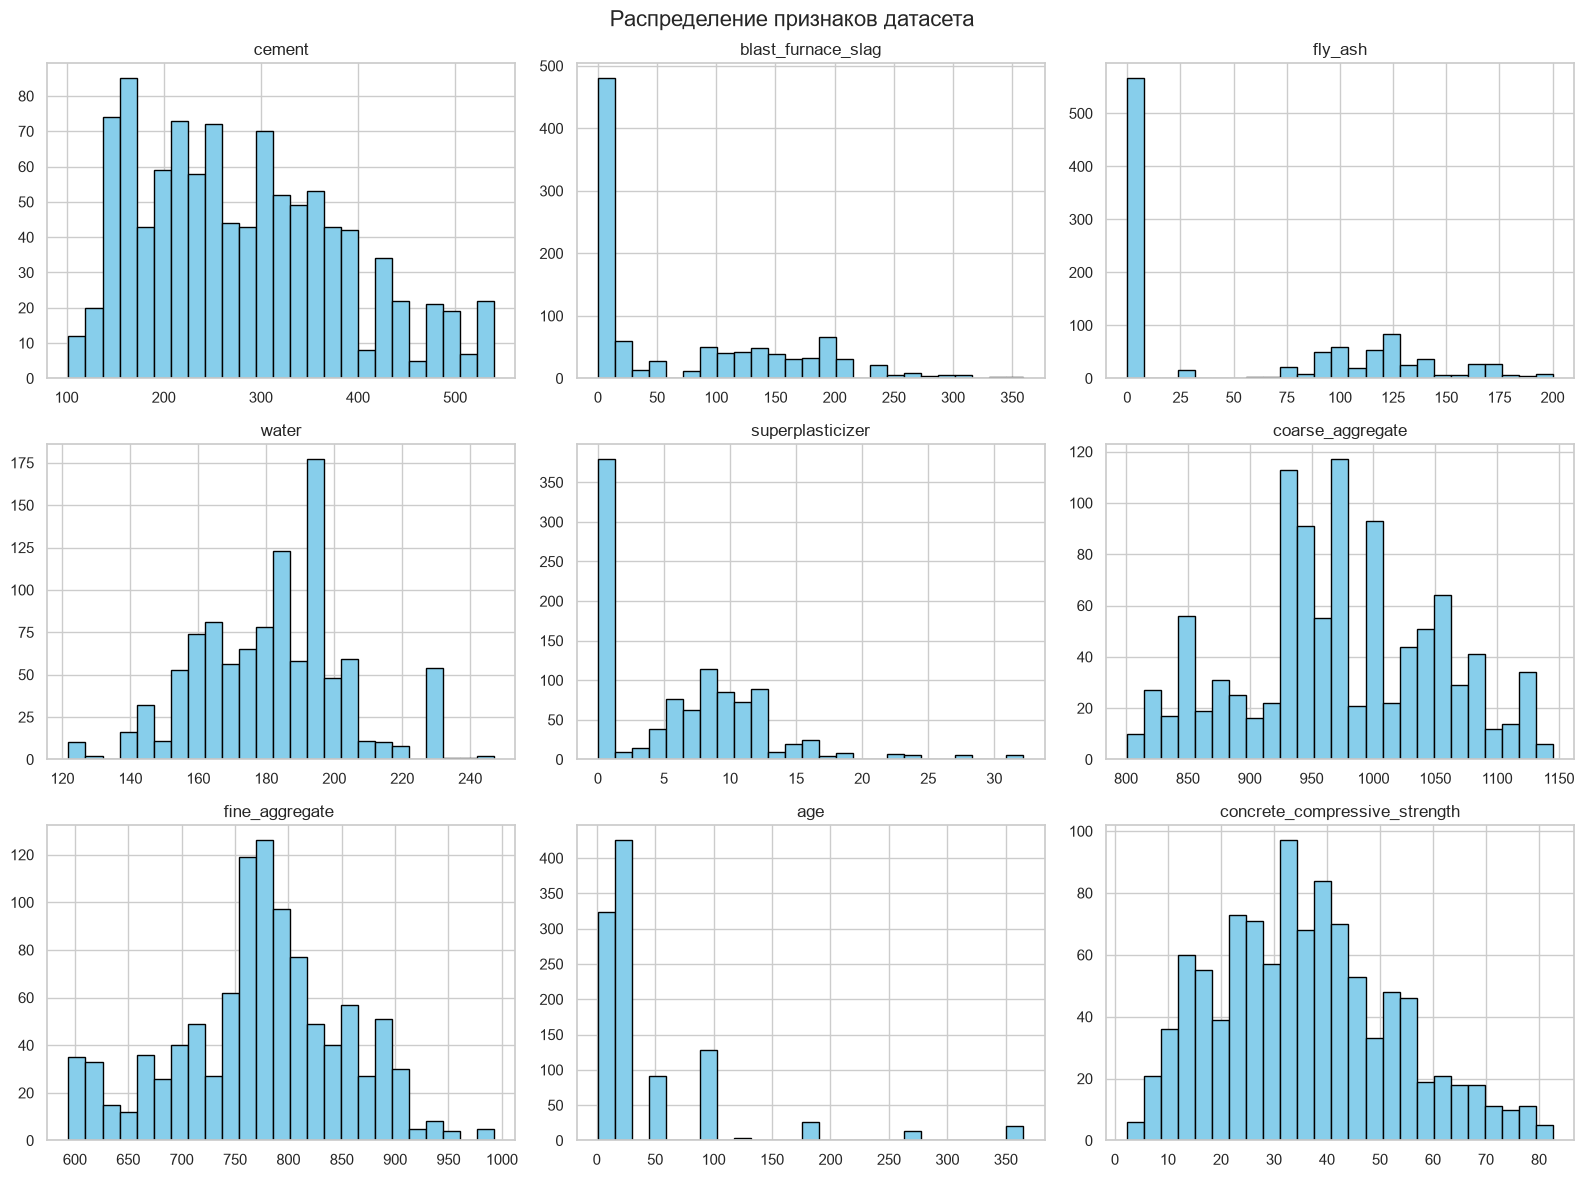

In [201]:
df.hist(
    bins=25,
    figsize=(16, 12),
    edgecolor="black",
    color="skyblue"
)

plt.suptitle(
    "Распределение признаков датасета",
    fontsize=16
)

plt.tight_layout()
plt.show()

### Анализ распределения признаков

Для визуального исследования структуры датасета построены гистограммы распределения всех числовых переменных.

Гистограммы позволяют определить форму распределения, наличие асимметрии и концентрацию наблюдений в определённых диапазонах.

Для компонентов бетонной смеси возможны несимметричные распределения, поскольку рецептуры могут содержать различное количество отдельных добавок, включая нулевое.

Полученные результаты показывают необходимость дальнейшего исследования взаимосвязей между признаками, а также обосновывают использование масштабирования перед применением методов, чувствительных к масштабу переменных.

Целевая переменная: concrete_compressive_strength


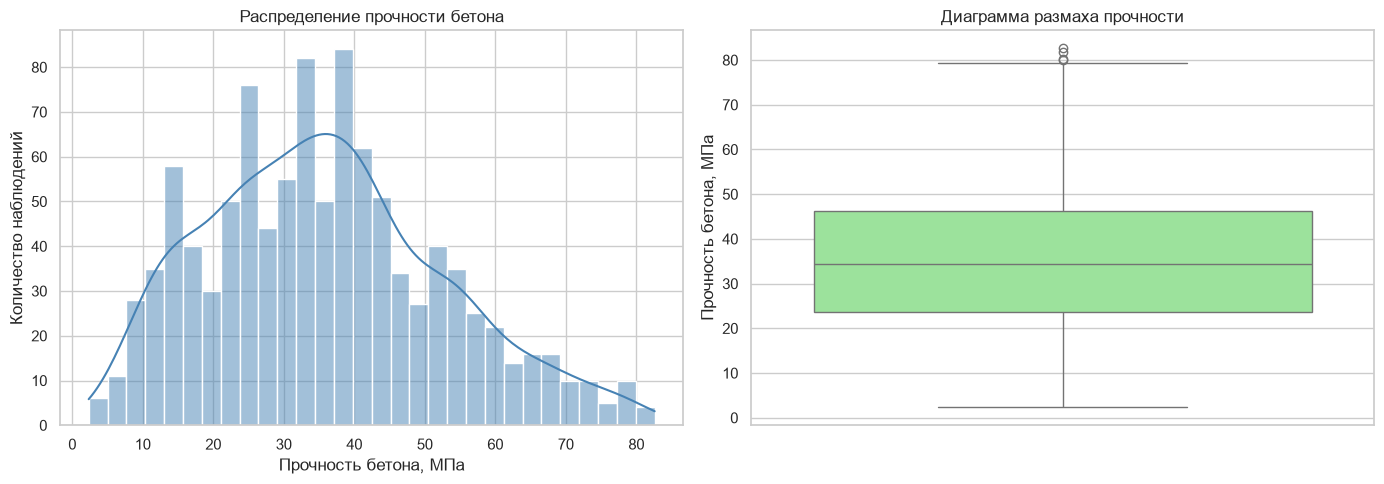

In [202]:
target_column = df.columns[-1]

print("Целевая переменная:", target_column)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(
    df[target_column],
    bins=30,
    kde=True,
    color="steelblue",
    ax=axes[0]
)

axes[0].set_title("Распределение прочности бетона")
axes[0].set_xlabel("Прочность бетона, МПа")
axes[0].set_ylabel("Количество наблюдений")

sns.boxplot(
    y=df[target_column],
    color="lightgreen",
    ax=axes[1]
)

axes[1].set_title("Диаграмма размаха прочности")
axes[1].set_ylabel("Прочность бетона, МПа")

plt.tight_layout()
plt.show()

### Анализ распределения целевой переменной

По результатам визуализации установлено, что распределение прочности бетона является одновершинным, с умеренной правосторонней асимметрией. Наибольшая концентрация наблюдений приходится приблизительно на диапазон 20–50 МПа, а максимум плотности располагается около 35 МПа.

Средняя прочность составляет 35,82 МПа, а медиана — 34,44 МПа. Близость этих величин указывает на отсутствие сильной асимметрии распределения.

Диаграмма размаха показывает, что 50% наблюдений находятся между первым квартилем (23,71 МПа) и третьим квартилем (46,14 МПа).

В верхней части диаграммы наблюдаются потенциальные выбросы, соответствующие образцам с высокой прочностью, приблизительно 80–83 МПа.

На данном этапе выбросы не удаляются, поскольку они могут отражать реальные характеристики высокопрочных бетонных смесей.

Таким образом, целевая переменная имеет достаточно широкий диапазон значений и подходит для исследования методами регрессионного анализа.

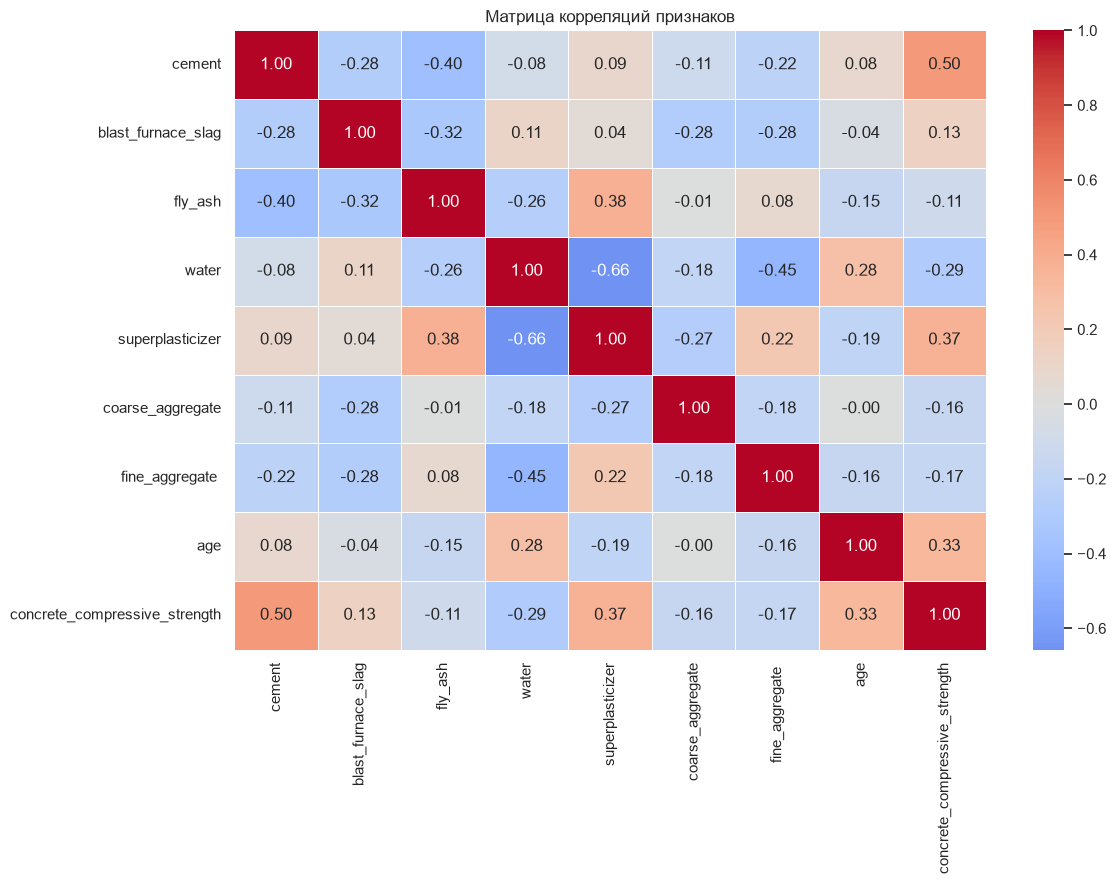

In [203]:
correlation_matrix = df.corr(numeric_only=True)

plt.figure(figsize=(12, 9))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    linewidths=0.5
)

plt.title("Матрица корреляций признаков")
plt.tight_layout()
plt.show()

### Корреляционный анализ 

Для выявления линейных взаимосвязей между переменными построена корреляционная матрица Пирсона.

Наиболее выраженная положительная корреляция с прочностью бетона наблюдается у содержания цемента (r = 0,50). Умеренная положительная связь также обнаружена у суперпластификатора (r = 0,37) и возраста бетона (r = 0,33).

Наиболее заметная отрицательная корреляция с прочностью характерна для содержания воды (r = −0,29).

Среди независимых признаков наиболее сильная по модулю парная корреляция наблюдается между количеством воды и суперпластификатора (r = −0,66). Также обнаружены отрицательные корреляции между количеством воды и мелкого заполнителя (r = −0,45), содержанием цемента и летучей золы (r = −0,40).

Таким образом, между отдельными входными переменными наблюдаются линейные зависимости, указывающие на возможность мультиколлинеарности. Для её дополнительной оценки проведён расчёт коэффициентов VIF.

,Корреляция с прочностью бетона
cement,0.498
superplasticizer,0.366
age,0.329
blast_furnace_slag,0.135
fly_ash,-0.106
coarse_aggregate,-0.165
fine_aggregate,-0.167
water,-0.290


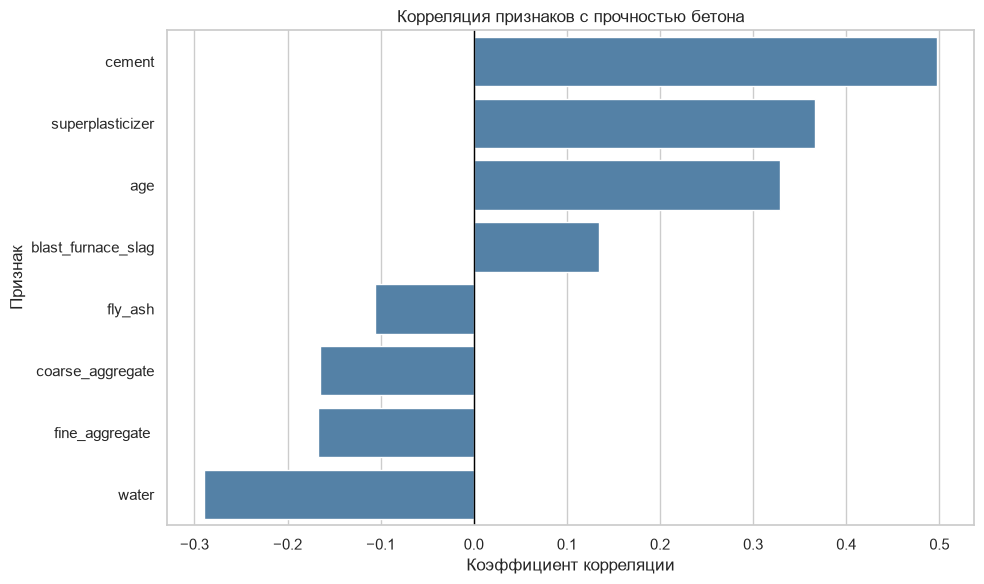

In [204]:
target_correlations = (
    correlation_matrix[target_column]
    .drop(target_column)
    .sort_values(ascending=False)
)

display(
    target_correlations.to_frame(
        name="Корреляция с прочностью бетона"
    ).round(3)
)

plt.figure(figsize=(10, 6))

sns.barplot(
    x=target_correlations.values,
    y=target_correlations.index,
    color="steelblue"
)

plt.axvline(0, color="black", linewidth=1)
plt.title("Корреляция признаков с прочностью бетона")
plt.xlabel("Коэффициент корреляции")
plt.ylabel("Признак")
plt.tight_layout()
plt.show()

### Связь входных признаков с целевой переменной

Для оценки влияния входных переменных на прогнозируемую прочность бетона рассчитаны коэффициенты корреляции Пирсона между каждым признаком и целевой переменной.

Полученные коэффициенты упорядочены по убыванию, что позволяет определить признаки с наиболее выраженными положительными и отрицательными линейными связями.

Следует учитывать, что корреляция не означает причинно-следственную зависимость. Кроме того, коэффициент Пирсона отражает только линейную составляющую взаимосвязи.

На следующем этапе проводится дополнительная проверка мультиколлинеарности с помощью VIF.

In [205]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant

X = df.drop(columns=[target_column])
y = df[target_column]

X_vif = add_constant(X)

vif_data = pd.DataFrame({
    "Признак": X.columns,
    "VIF": [
        variance_inflation_factor(
            X_vif.values,
            i
        )
        for i in range(1, X_vif.shape[1])
    ]
})

vif_data = vif_data.sort_values(
    by="VIF",
    ascending=False
)

display(vif_data.round(3))

,Признак,VIF
0,cement,7.489
1,blast_furnace_slag,7.277
6,fine_aggregate,7.005
3,water,7.004
2,fly_ash,6.171
5,coarse_aggregate,5.075
4,superplasticizer,2.964
7,age,1.118


### Оценка мультиколлинеарности с помощью VIF 20

Для диагностики мультиколлинеарности независимых признаков рассчитаны коэффициенты инфляции дисперсии VIF.

Наибольшие значения получены для содержания цемента (VIF = 7,489), доменного шлака (VIF = 7,277), мелкого заполнителя (VIF = 7,005) и воды (VIF = 7,004).

Также повышенные показатели наблюдаются у летучей золы (VIF = 6,171) и крупного заполнителя (VIF = 5,075).

Таким образом, 6 из 8 независимых переменных имеют значения VIF выше 5, что указывает на заметную мультиколлинеарность.

При этом максимальное значение VIF не превышает 10, поэтому мультиколлинеарность нельзя считать критической по выбранным пороговым значениям.

Для дальнейшего исследования влияния мультиколлинеарности и снижения размерности признаков будет применён метод главных компонент (PCA). Он позволит преобразовать исходные зависимые признаки в набор взаимно некоррелированных главных компонент.

In [206]:
from sklearn.model_selection import train_test_split

X = df.drop(columns=[target_column])
y = df[target_column]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Обучающая выборка:", X_train.shape)
print("Тестовая выборка:", X_test.shape)
print("Целевая переменная train:", y_train.shape)
print("Целевая переменная test:", y_test.shape)

Обучающая выборка: (824, 8)
Тестовая выборка: (206, 8)
Целевая переменная train: (824,)
Целевая переменная test: (206,)


### Разделение данных на обучающую и тестовую выборки

Для оценки качества моделей исходный набор данных разделён на обучающую и тестовую выборки с помощью функции `train_test_split` библиотеки scikit-learn.

80% наблюдений (824 записи) используются для обучения моделей, остальные 20% (206 записей) — для независимой оценки их качества.

В качестве входных данных используются восемь характеристик бетонной смеси. Целевой переменной является прочность бетона на сжатие.

Параметр `random_state=42` обеспечивает воспроизводимость результатов.

Тестовая выборка не используется для обучения моделей, настройки гиперпараметров или расчёта параметров стандартизации.

In [207]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.model_selection import GridSearchCV, KFold

cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

alpha_values = np.logspace(-3, 3, 13)

models = {
    "Linear Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LinearRegression())
    ]),
    "Ridge": Pipeline([
        ("scaler", StandardScaler()),
        ("model", Ridge())
    ]),
    "Lasso": Pipeline([
        ("scaler", StandardScaler()),
        ("model", Lasso(max_iter=100000))
    ])
}

trained_models = {}

trained_models["Linear Regression"] = models[
    "Linear Regression"
].fit(X_train, y_train)

for name in ["Ridge", "Lasso"]:
    search = GridSearchCV(
        estimator=models[name],
        param_grid={"model__alpha": alpha_values},
        cv=cv,
        scoring="neg_root_mean_squared_error",
        n_jobs=-1
    )

    search.fit(X_train, y_train)
    trained_models[name] = search.best_estimator_

    print(name)
    print("Лучшее alpha:", search.best_params_["model__alpha"])
    print("CV RMSE:", round(-search.best_score_, 3))
    print()

Ridge
Лучшее alpha: 0.31622776601683794
CV RMSE: 10.627

Lasso
Лучшее alpha: 0.001
CV RMSE: 10.627



### Построение регрессионных моделей

Для прогнозирования прочности бетона реализованы три модели: Linear Regression, Ridge Regression и Lasso Regression.

Перед обучением выполняется стандартизация входных признаков с использованием `StandardScaler`. Преобразование включено в конвейер `Pipeline`, что предотвращает утечку информации при кросс-валидации.

Для Ridge и Lasso проведён подбор коэффициента регуляризации `alpha` с использованием `GridSearchCV`.

Применена пятикратная кросс-валидация (`KFold`) с перемешиванием данных. В качестве критерия выбора гиперпараметров использована минимизация RMSE.

Подбор гиперпараметров выполняется исключительно на обучающей выборке. Тестовые данные сохраняются для итоговой проверки качества моделей.

In [208]:
from sklearn.metrics import (
    mean_squared_error,
    r2_score,
    mean_absolute_percentage_error
)
from sklearn.model_selection import cross_validate

results = []
predictions = {}

for name, model in trained_models.items():

    y_pred = model.predict(X_test)
    predictions[name] = y_pred

    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    r2 = r2_score(y_test, y_pred)
    mape = mean_absolute_percentage_error(y_test, y_pred) * 100

    cv_scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring={
            "rmse": "neg_root_mean_squared_error",
            "r2": "r2",
            "mape": "neg_mean_absolute_percentage_error"
        },
        n_jobs=-1
    )

    results.append({
        "Модель": name,
        "RMSE": rmse,
        "R²": r2,
        "MAPE (%)": mape,
        "CV RMSE": -cv_scores["test_rmse"].mean(),
        "CV R²": cv_scores["test_r2"].mean(),
        "CV MAPE (%)": -cv_scores["test_mape"].mean() * 100
    })

results_df = pd.DataFrame(results)

display(results_df.round(3))

,Модель,RMSE,R²,MAPE (%),CV RMSE,CV R²,CV MAPE (%)
0,Linear Regression,9.796,0.628,29.273,10.627,0.597,32.332
1,Ridge,9.796,0.628,29.294,10.627,0.597,32.349
2,Lasso,9.796,0.628,29.281,10.627,0.597,32.337


### Оценка качества регрессионных моделей

Для оценки качества прогнозирования использованы метрики RMSE, R² и MAPE, а также пятикратная кросс-валидация.

На тестовой выборке модель Linear Regression показала RMSE = 9,796 МПа, R² = 0,628 и MAPE = 29,273%.

Модель Ridge продемонстрировала практически идентичные результаты: RMSE = 9,796 МПа, R² = 0,628 и MAPE = 29,294%.

Для модели Lasso получены RMSE = 9,796 МПа, R² = 0,628 и MAPE = 29,281%.

Таким образом, применение L1- и L2-регуляризации практически не повлияло на качество прогнозирования по сравнению с обычной линейной регрессией.

Среднее значение RMSE при пятикратной кросс-валидации составило около 10,627 МПа, а средний R² — 0,597. Данные результаты свидетельствуют об относительно стабильном качестве моделей на различных разбиениях обучающей выборки.

Значение R² около 0,63 указывает на то, что линейные модели способны объяснить существенную часть изменчивости прочности бетона, однако сохраняется заметная доля необъяснённой вариации.

Возможной причиной ограниченной точности является наличие нелинейных зависимостей между характеристиками бетонной смеси и её прочностью.

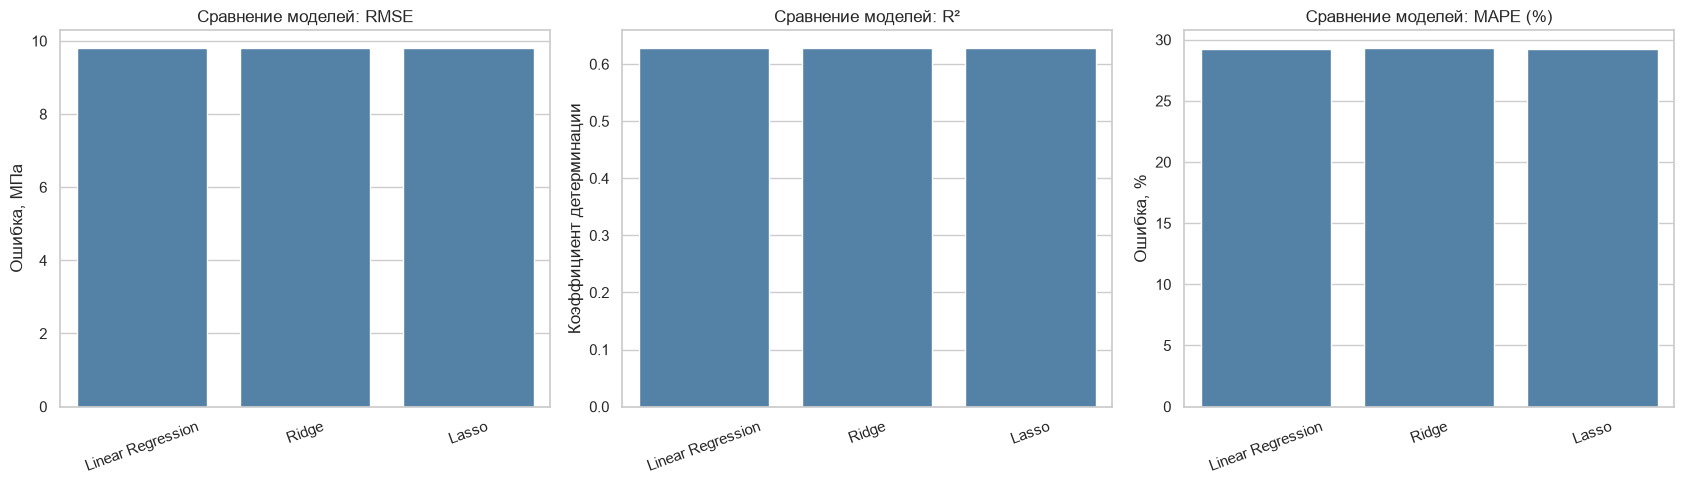

In [209]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

metrics = ["RMSE", "R²", "MAPE (%)"]

for ax, metric in zip(axes, metrics):
    sns.barplot(
        data=results_df,
        x="Модель",
        y=metric,
        color="steelblue",
        ax=ax
    )

    ax.set_title(f"Сравнение моделей: {metric}")
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=20)

    if metric == "RMSE":
        ax.set_ylabel("Ошибка, МПа")
    elif metric == "MAPE (%)":
        ax.set_ylabel("Ошибка, %")
    else:
        ax.set_ylabel("Коэффициент детерминации")

plt.tight_layout()
plt.show()

### Сравнение качества моделей

Для наглядного сравнения моделей построены столбчатые диаграммы значений RMSE, R² и MAPE на тестовой выборке.

Меньшие значения RMSE и MAPE соответствуют более точным прогнозам, тогда как для R² предпочтительны большие значения.

Графическое представление результатов позволяет выявить различия между обычной линейной регрессией и регрессионными моделями с L1- и L2-регуляризацией.

На основе полученных показателей будет выбрана модель с наилучшим качеством прогнозирования. Далее результаты будут сопоставлены с моделями, обученными после применения PCA.

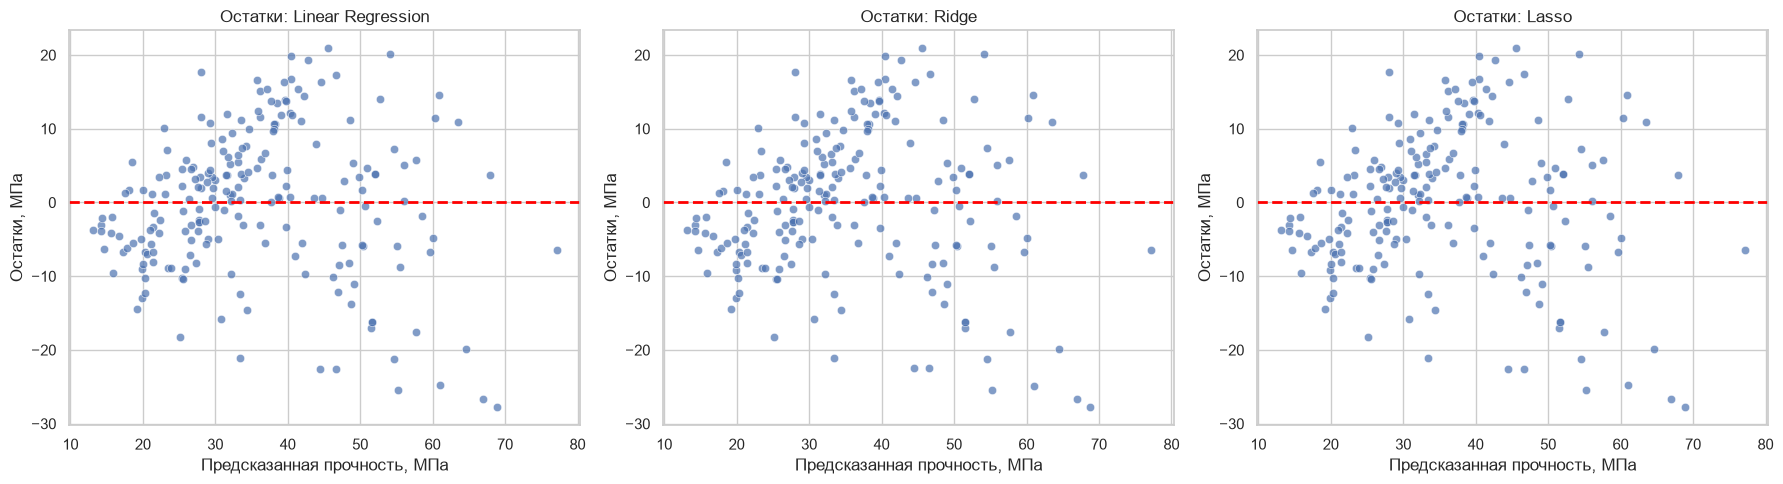

In [210]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (name, model) in zip(axes, trained_models.items()):

    y_pred = model.predict(X_test)
    residuals = y_test - y_pred

    sns.scatterplot(
        x=y_pred,
        y=residuals,
        ax=ax,
        alpha=0.7
    )

    ax.axhline(
        y=0,
        color="red",
        linestyle="--",
        linewidth=2
    )

    ax.set_title(f"Остатки: {name}")
    ax.set_xlabel("Предсказанная прочность, МПа")
    ax.set_ylabel("Остатки, МПа")

plt.tight_layout()
plt.show()

### Анализ остатков регрессионных моделей

Для исследования качества построенных моделей проведён визуальный анализ остатков Linear Regression, Ridge и Lasso.

На графиках заметно, что остатки распределены не полностью случайным образом относительно горизонтальной линии нулевой ошибки.

При относительно низких прогнозируемых значениях прочности преобладают отрицательные остатки, в среднем диапазоне наблюдается концентрация положительных остатков, а при более высоких прогнозируемых значениях вновь появляются значительные отрицательные отклонения.

Кроме того, наблюдается изменение разброса остатков, что позволяет предположить наличие гетероскедастичности.

Расположение точек также указывает на возможную нелинейную структуру зависимостей между признаками и целевой переменной.

Графики остатков всех трёх моделей практически совпадают, что согласуется с близкими значениями метрик качества прогнозирования.

Таким образом, линейные модели имеют определённые ограничения при прогнозировании прочности бетона. Для дополнительной проверки постоянства дисперсии остатков применяется тест Бройша — Пагана.

In [211]:

import statsmodels.api as sm
from statsmodels.stats.diagnostic import het_breuschpagan

X_train_const = sm.add_constant(X_train)

ols_model = sm.OLS(y_train, X_train_const).fit()

residuals_ols = ols_model.resid

lm_stat, lm_pvalue, f_stat, f_pvalue = het_breuschpagan(
    residuals_ols,
    ols_model.model.exog
)

print("LM statistic:", round(lm_stat, 4))
print("p-value:", f"{lm_pvalue:.8g}")

if lm_pvalue < 0.05:
    print("Обнаружены признаки гетероскедастичности")
else:
    print("Нет оснований отвергнуть гипотезу о гомоскедастичности")


LM statistic: 111.1615
p-value: 2.1971399e-20
Обнаружены признаки гетероскедастичности


### Проверка гетероскедастичности с помощью теста Бройша — Пагана

Для проверки постоянства дисперсии остатков линейной регрессионной модели использован тест Бройша — Пагана (Breusch–Pagan).

Тест проведён на остатках модели Ordinary Least Squares (OLS), обученной на тренировочной выборке.

В рамках теста рассматриваются две гипотезы:

- **H₀ (нулевая гипотеза):** дисперсия случайных ошибок постоянна (гомоскедастичность).
- **H₁ (альтернативная гипотеза):** дисперсия случайных ошибок зависит от объясняющих переменных (гетероскедастичность).

Для проверки гипотез выбран уровень значимости α = 0,05.

**Полученные результаты:**

- LM statistic = 111,1615.
- p-value = 2,1971 × 10⁻²⁰.

Полученное значение p-value значительно меньше установленного уровня значимости 0,05. Следовательно, нулевая гипотеза о постоянстве дисперсии ошибок отвергается.

Таким образом, результаты теста Бройша — Пагана свидетельствуют о статистически значимой гетероскедастичности остатков модели линейной регрессии.

Данный результат согласуется с ранее построенными графиками остатков, на которых наблюдаются неодинаковый разброс ошибок и определённая структура их распределения.

Наличие гетероскедастичности указывает на нарушение одной из классических предпосылок линейной регрессии. Это может снижать эффективность оценок коэффициентов и влиять на достоверность стандартных ошибок, доверительных интервалов и статистических тестов.

При этом наличие гетероскедастичности не означает, что модель полностью непригодна для прогнозирования, однако указывает на необходимость учитывать особенности распределения ошибок при интерпретации результатов.

**Вывод:** тест Бройша — Пагана подтвердил наличие выраженной гетероскедастичности в остатках модели OLS. Для дальнейшего улучшения модели могут рассматриваться нелинейные преобразования признаков и другие методы моделирования, учитывающие особенности зависимости прочности бетона от состава смеси.

In [212]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

scaler_pca = StandardScaler()

X_train_scaled = scaler_pca.fit_transform(X_train)
X_test_scaled = scaler_pca.transform(X_test)

pca_full = PCA()
pca_full.fit(X_train_scaled)

explained_variance = pca_full.explained_variance_ratio_
cumulative_variance = np.cumsum(explained_variance)

pca_info = pd.DataFrame({
    "Компонента": np.arange(1, len(explained_variance) + 1),
    "Доля дисперсии": explained_variance,
    "Накопленная доля": cumulative_variance
})

display(pca_info.round(4))

,Компонента,Доля дисперсии,Накопленная доля
0,1,0.2802,0.2802
1,2,0.1791,0.4593
2,3,0.1683,0.6276
3,4,0.1280,0.7556
4,5,0.1181,0.8737
5,6,0.0994,0.9731
6,7,0.0230,0.9961
7,8,0.0039,1.0000


### Стандартизация признаков и предварительный анализ PCA

Перед применением метода главных компонент выполнена стандартизация исходных независимых признаков с использованием StandardScaler.

Стандартизация приводит признаки к сопоставимому масштабу: на обучающей выборке их средние значения становятся близкими к нулю, а дисперсии — к единице.

Это необходимо, поскольку исходные переменные имеют различные диапазоны значений и единицы измерения.

После стандартизации выполнен предварительный PCA с восемью главными компонентами.

Для каждой компоненты рассчитана доля объяснённой дисперсии и накопленная доля объяснённой дисперсии.

Полученные показатели используются для выбора оптимального количества главных компонент и оценки возможности снижения размерности данных.

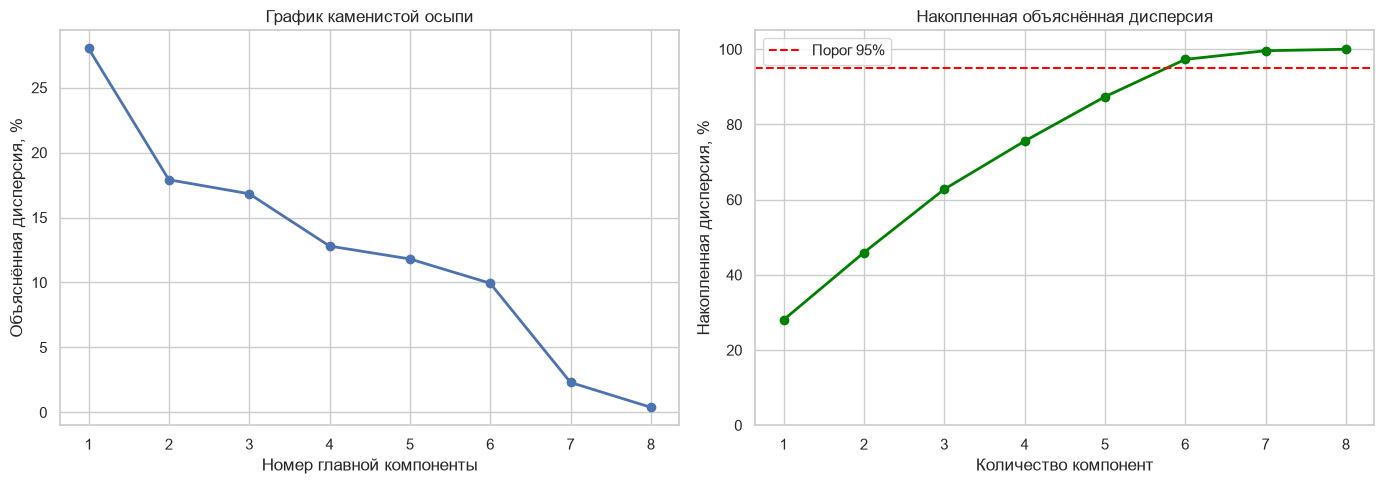

In [213]:
components = np.arange(1, len(explained_variance) + 1)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(
    components,
    explained_variance * 100,
    marker="o",
    linewidth=2
)

axes[0].set_title("График каменистой осыпи")
axes[0].set_xlabel("Номер главной компоненты")
axes[0].set_ylabel("Объяснённая дисперсия, %")
axes[0].set_xticks(components)
axes[0].grid(True)

axes[1].plot(
    components,
    cumulative_variance * 100,
    marker="o",
    linewidth=2,
    color="green"
)

axes[1].axhline(
    y=95,
    color="red",
    linestyle="--",
    label="Порог 95%"
)

axes[1].set_title("Накопленная объяснённая дисперсия")
axes[1].set_xlabel("Количество компонент")
axes[1].set_ylabel("Накопленная дисперсия, %")
axes[1].set_xticks(components)
axes[1].set_ylim(0, 105)
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

### Анализ графика каменистой осыпи

По результатам применения метода главных компонент (PCA) построен график каменистой осыпи и график накопленной объяснённой дисперсии.

Первая главная компонента объясняет 28,02% общей дисперсии стандартизованных признаков, вторая — 17,91%, третья — 16,83%.

Первые три компоненты суммарно объясняют 62,76% дисперсии, а первые пять — 87,37%.

При использовании шести главных компонент накопленная объяснённая дисперсия достигает 97,31%, что превышает выбранный порог 95%.

Седьмая и восьмая компоненты объясняют лишь 2,30% и 0,39% дисперсии соответственно. Поэтому их исключение позволяет уменьшить размерность данных при относительно небольшой потере общей дисперсии.

Таким образом, для дальнейшего построения регрессионных моделей выбраны шесть главных компонент.

In [214]:
n_components_95 = np.searchsorted(
    cumulative_variance,
    0.95
) + 1
print("Исходное количество признаков:", X_train.shape[1])
print("Количество компонент для 95% дисперсии:", n_components_95)
print(
    "Сохранённая доля дисперсии:",
    round(cumulative_variance[n_components_95 - 1] * 100, 2),
    "%"
)
pca = PCA(n_components=n_components_95)
X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)
print("Размерность train после PCA:", X_train_pca.shape)
print("Размерность test после PCA:", X_test_pca.shape)

pca_columns = [
    f"PC{i+1}" for i in range(n_components_95)
]

X_train_pca_df = pd.DataFrame(
    X_train_pca,
    columns=pca_columns,
    index=X_train.index
)
display(X_train_pca_df.head())

Исходное количество признаков: 8
Количество компонент для 95% дисперсии: 6
Сохранённая доля дисперсии: 97.31 %
Размерность train после PCA: (824, 6)
Размерность test после PCA: (206, 6)


,PC1,PC2,PC3,PC4,PC5,PC6
995,-1.175572,1.222351,-0.835258,-0.737277,-1.206229,0.292764
507,-0.802163,0.275023,1.140729,0.816967,-1.382623,-1.513356
334,-1.610347,-1.226806,-0.458107,-0.707043,-0.240320,-0.114362
848,-0.414377,1.429764,0.068798,1.144081,-0.185305,-0.826430
294,-1.857663,-0.789078,-1.287309,-0.875359,0.020018,0.443568


### Снижение размерности признаков с помощью PCA

После стандартизации исходных данных выполнено преобразование восьми независимых признаков в пространство главных компонент.

На основе критерия сохранения не менее 95% объяснённой дисперсии выбраны шесть главных компонент.

В результате размерность пространства признаков сокращена с 8 до 6, то есть на 25%.

Выбранные компоненты сохраняют 97,31% дисперсии исходных стандартизованных переменных.

Главные компоненты являются взаимно ортогональными и некоррелированными на обучающих данных, использованных для построения PCA. Благодаря этому устраняется линейная мультиколлинеарность между преобразованными признаками.

Полученные главные компоненты далее используются для обучения моделей Linear Regression, Ridge и Lasso. Их качество будет сопоставлено с результатами моделей, обученных на исходных признаках.

In [215]:
from sklearn.pipeline import Pipeline
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.model_selection import GridSearchCV

pca_models = {
    "Linear Regression": LinearRegression(),
    "Ridge": Ridge(),
    "Lasso": Lasso(max_iter=100000)
}

trained_pca_models = {}
best_pca_alphas = {}

for name, estimator in pca_models.items():

    pipeline = Pipeline([
        ("scaler", StandardScaler()),
        ("pca", PCA(n_components=0.95)),
        ("model", estimator)
    ])

    if name == "Linear Regression":
        pipeline.fit(X_train, y_train)
        trained_pca_models[name] = pipeline

    else:
        search = GridSearchCV(
            pipeline,
            param_grid={"model__alpha": alpha_values},
            cv=cv,
            scoring="neg_root_mean_squared_error",
            n_jobs=-1
        )

        search.fit(X_train, y_train)

        trained_pca_models[name] = search.best_estimator_
        best_pca_alphas[name] = search.best_params_["model__alpha"]

for name, model in trained_pca_models.items():
    print(name)
    print(
        "Количество компонент:",
        model.named_steps["pca"].n_components_
    )

    if name in best_pca_alphas:
        print("Лучшее alpha:", best_pca_alphas[name])

    print()

Linear Regression
Количество компонент: 6

Ridge
Количество компонент: 6
Лучшее alpha: 1.0

Lasso
Количество компонент: 6
Лучшее alpha: 0.01



### Повторное обучение регрессионных моделей после PCA

После снижения размерности признаков выполнено повторное обучение моделей Linear Regression, Ridge и Lasso.

В отличие от первоначального эксперимента, теперь входные переменные предварительно преобразуются методом главных компонент.

Для каждой модели используется конвейер Pipeline, объединяющий стандартизацию данных, PCA и регрессионный алгоритм.

Количество компонент определяется автоматически по критерию сохранения не менее 95% дисперсии. На полной обучающей выборке ранее было установлено, что данному критерию соответствуют шесть главных компонент.

Для моделей Ridge и Lasso повторно выполняется подбор коэффициента регуляризации с помощью GridSearchCV.

Все этапы преобразования признаков и настройки гиперпараметров выполняются исключительно на обучающих данных, что предотвращает утечку информации из тестовой выборки.

In [216]:
pca_results = []
pca_predictions = {}

for name, model in trained_pca_models.items():

    y_pred = model.predict(X_test)
    pca_predictions[name] = y_pred

    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    r2 = r2_score(y_test, y_pred)
    mape = mean_absolute_percentage_error(y_test, y_pred) * 100

    pca_results.append({
        "Модель": name,
        "RMSE": rmse,
        "R²": r2,
        "MAPE (%)": mape
    })

pca_results_df = pd.DataFrame(pca_results)

display(pca_results_df.round(3))

,Модель,RMSE,R²,MAPE (%)
0,Linear Regression,10.552,0.568,32.610
1,Ridge,10.551,0.568,32.632
2,Lasso,10.552,0.568,32.639


### Оценка качества моделей после PCA

После применения метода главных компонент выполнено прогнозирование прочности бетона на тестовой выборке.

Для моделей Linear Regression, Ridge и Lasso рассчитаны показатели RMSE, R² и MAPE.

При оценке используются те же 206 тестовых наблюдений, что и в эксперименте до применения PCA.

Это обеспечивает сопоставимость результатов и позволяет оценить влияние преобразования признаков на качество прогнозирования.

Следующим этапом проводится количественное и графическое сравнение моделей, обученных на исходных признаках и главных компонентах.

In [217]:
comparison_df = results_df[
    ["Модель", "RMSE", "R²", "MAPE (%)"]
].merge(
    pca_results_df,
    on="Модель",
    suffixes=("_до_PCA", "_после_PCA")
)

comparison_df["Изменение RMSE"] = (
    comparison_df["RMSE_после_PCA"] -
    comparison_df["RMSE_до_PCA"]
)

comparison_df["Изменение R²"] = (
    comparison_df["R²_после_PCA"] -
    comparison_df["R²_до_PCA"]
)

comparison_df["Изменение MAPE"] = (
    comparison_df["MAPE (%)_после_PCA"] -
    comparison_df["MAPE (%)_до_PCA"]
)

display(comparison_df.round(3))


,Модель,RMSE_до_PCA,R²_до_PCA,MAPE (%)_до_PCA,RMSE_после_PCA,R²_после_PCA,MAPE (%)_после_PCA,Изменение RMSE,Изменение R²,Изменение MAPE
0,Linear Regression,9.796,0.628,29.273,10.552,0.568,32.610,0.755,-0.06,3.337
1,Ridge,9.796,0.628,29.294,10.551,0.568,32.632,0.755,-0.06,3.338
2,Lasso,9.796,0.628,29.281,10.552,0.568,32.639,0.755,-0.06,3.358


### Сравнение качества моделей до и после PCA

Для оценки эффективности метода главных компонент выполнено сравнение моделей Linear Regression, Ridge и Lasso, обученных на исходных и преобразованных признаках.

До применения PCA все три модели продемонстрировали практически одинаковые показатели качества: RMSE = 9,796 МПа, R² = 0,628 и MAPE около 29,3%.

После преобразования исходных восьми признаков в шесть главных компонент качество прогнозирования несколько снизилось.

Значение RMSE увеличилось приблизительно до 10,552 МПа, коэффициент детерминации R² уменьшился до 0,568, а MAPE увеличилась приблизительно до 32,6%.

Таким образом, среднеквадратичная ошибка выросла примерно на 7,7%, а коэффициент детерминации снизился на 0,060.

Несмотря на сохранение 97,31% дисперсии исходных признаков, исключённые компоненты могли содержать информацию, значимую для прогнозирования прочности бетона.

Регуляризованные модели Ridge и Lasso не продемонстрировали существенных преимуществ перед обычной линейной регрессией как до, так и после применения PCA.

Следовательно, PCA позволил снизить размерность пространства признаков и устранить линейную корреляцию между главными компонентами, однако при выбранном пороге объяснённой дисперсии не улучшил качество прогнозирования.

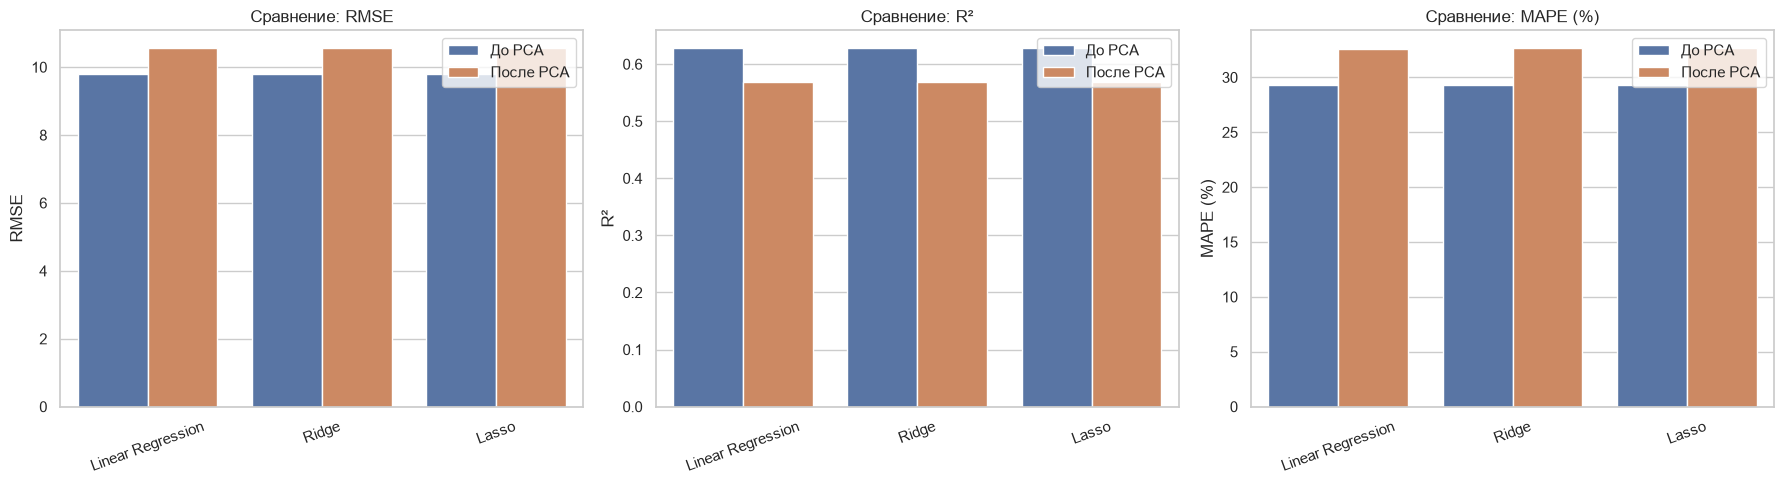

In [218]:
plot_data = pd.concat([
    results_df[
        ["Модель", "RMSE", "R²", "MAPE (%)"]
    ].assign(Признаки="До PCA"),

    pca_results_df.assign(Признаки="После PCA")
], ignore_index=True)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, metric in zip(
    axes,
    ["RMSE", "R²", "MAPE (%)"]
):

    sns.barplot(
        data=plot_data,
        x="Модель",
        y=metric,
        hue="Признаки",
        ax=ax
    )

    ax.set_title(f"Сравнение: {metric}")
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=20)
    ax.legend(title="")

plt.tight_layout()
plt.show()

### Графическое сравнение регрессионных моделей

На диаграммах представлено сравнение метрик RMSE, R² и MAPE для моделей Linear Regression, Ridge и Lasso до и после применения метода главных компонент.

Для всех трёх алгоритмов наблюдается практически одинаковая тенденция: после PCA значение RMSE увеличивается, коэффициент детерминации R² уменьшается, а процентная ошибка MAPE возрастает.

Полученные результаты свидетельствуют о небольшом ухудшении точности прогнозирования при уменьшении количества признаков с восьми до шести.

При этом снижение размерности позволило получить компактное представление входных данных без линейной корреляции между главными компонентами на обучающей выборке.

Таким образом, применение PCA в данной задаче представляет собой компромисс между сокращением размерности и точностью прогнозирования. Если основным критерием является точность, предпочтительнее использовать исходные восемь признаков.

In [219]:
from sklearn.model_selection import cross_validate

pca_cv_results = []

for name, model in trained_pca_models.items():

    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring={
            "rmse": "neg_root_mean_squared_error",
            "r2": "r2",
            "mape": "neg_mean_absolute_percentage_error"
        },
        n_jobs=-1
    )

    pca_cv_results.append({
        "Модель": name,
        "CV RMSE после PCA": -scores["test_rmse"].mean(),
        "CV R² после PCA": scores["test_r2"].mean(),
        "CV MAPE (%) после PCA": (
            -scores["test_mape"].mean() * 100
        )
    })

pca_cv_df = pd.DataFrame(pca_cv_results)
display(pca_cv_df.round(3))

,Модель,CV RMSE после PCA,CV R² после PCA,CV MAPE (%) после PCA
0,Linear Regression,11.27,0.547,34.833
1,Ridge,11.27,0.547,34.853
2,Lasso,11.27,0.547,34.850


### Анализ результатов кросс-валидации после PCA

Для оценки устойчивости регрессионных моделей после применения PCA проведена пятикратная кросс-валидация.

Все три модели продемонстрировали практически одинаковые результаты.

Среднее значение RMSE после PCA составило 11,270 МПа, коэффициент детерминации R² — 0,547, а MAPE — приблизительно 34,8%.

До применения PCA соответствующие показатели составляли RMSE = 10,627 МПа, R² = 0,597 и MAPE около 32,3%.

Таким образом, после применения метода главных компонент средняя ошибка RMSE увеличилась приблизительно на 6,05%, коэффициент детерминации снизился на 0,050, а средняя абсолютная процентная ошибка выросла примерно на 2,5 процентного пункта.

Полученные результаты согласуются с оценкой качества моделей на тестовой выборке и подтверждают, что при выбранном количестве главных компонент снижение размерности сопровождается ухудшением точности прогнозирования.

При этом PCA позволил уменьшить количество признаков с восьми до шести и сохранить 97,31% дисперсии исходных стандартизованных данных.

Следовательно, в рассматриваемой задаче применение PCA обеспечивает уменьшение размерности и устранение линейной корреляции между компонентами, но не приводит к улучшению качества регрессионных моделей.

## Заключение

В ходе выполнения лабораторной работы были изучены основные методы регрессионного анализа и исследовано влияние снижения размерности признаков на качество прогнозирования.

Для проведения экспериментов использован набор данных Concrete Compressive Strength, содержащий 1030 наблюдений и 8 независимых числовых признаков. Целевой переменной являлась прочность бетона на сжатие, измеряемая в мегапаскалях.

На первом этапе выполнены загрузка данных, первичный статистический анализ, исследование распределений переменных и корреляционный анализ.

Установлено, что наиболее выраженная положительная корреляция с прочностью бетона наблюдается у содержания цемента (r = 0,50). Для содержания суперпластификатора и возраста бетона получены коэффициенты корреляции 0,37 и 0,33 соответственно.

По результатам расчёта коэффициентов VIF установлено наличие заметной мультиколлинеарности: у шести из восьми признаков значение VIF превышает 5.

Далее построены три регрессионные модели: Linear Regression, Ridge и Lasso. Для обучения использовано 80% данных, для тестирования — 20%. Дополнительно применена пятикратная кросс-валидация.

На исходных признаках все три модели показали практически одинаковое качество. Значение RMSE составило около 9,796 МПа, коэффициент детерминации R² — 0,628, а средняя абсолютная процентная ошибка MAPE — около 29,3%.

Анализ остатков показал наличие систематической структуры и неодинакового разброса ошибок. Тест Бройша — Пагана выявил статистически значимые признаки гетероскедастичности для всех трёх моделей при уровне значимости 0,05.

Для снижения размерности применён метод главных компонент (PCA). Предварительно выполнена стандартизация независимых переменных.

По результатам анализа объяснённой дисперсии выбраны шесть главных компонент, сохраняющие 97,31% общей дисперсии исходных стандартизованных признаков. Таким образом, размерность сокращена с восьми до шести признаков, то есть на 25%.

После повторного обучения моделей на главных компонентах наблюдалось некоторое ухудшение качества прогнозирования. RMSE увеличилась примерно до 10,552 МПа, R² снизился до 0,568, а MAPE выросла примерно до 32,6%.

Полученные результаты показывают, что применение PCA эффективно для снижения размерности и устранения линейной корреляции между компонентами, но не гарантирует повышения точности регрессионных моделей.

## Список использованных источников
1. Concrete Compressive Strength Data Set. Kaggle. https://www.kaggle.com/datasets/elikplim/concrete-compressive-strength-data-set

2. Scikit-learn Documentation. https://scikit-learn.org/stable/

3. Scikit-learn. Principal Component Analysis. https://scikit-learn.org/stable/modules/decomposition.html#pca

4. Pandas Documentation. https://pandas.pydata.org/docs/

5. Statsmodels Documentation. https://www.statsmodels.org/stable/